# IntruAegis: pelatihan model IDS (Random Forest, CIC-IDS2017)

Notebook ini mengerjakan bagian Muhamad Rifqi Nurjaman : memuat dataset, membersihkan data, melatih Random Forest, mengevaluasi, dan mengekspor artefak ke Google Drive untuk dipakai tim.

**Cara pakai:** Runtime → Run all. Training (±17 menit) hanya berjalan jika `model.joblib` belum ada atau `RETRAIN = True`.

**Prasyarat:** `archive.zip` (dataset CIC-IDS2017 versi MachineLearningCSV dari Kaggle) ada di `IntruAegis/data/` di Google Drive.

## 1. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, glob, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, accuracy_score)

BASE = "/content/drive/MyDrive/IntruAegis"
ZIP_PATH = f"{BASE}/data/archive.zip"
CLEAN_PATH = f"{BASE}/data/cicids2017_clean.parquet"
ART = f"{BASE}/artifacts"
os.makedirs(ART, exist_ok=True)

RETRAIN = False        # True = latih ulang (±17 menit); False = pakai model.joblib bila sudah ada
RANDOM_STATE = 42

Mounted at /content/drive


## 2. Memuat dataset mentah
Delapan file CSV digabung menjadi satu DataFrame. Encoding `latin-1` dipakai karena label Web Attack mengandung karakter non-ASCII.

In [2]:
import zipfile
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("/content/data")

dfs = []
for f in sorted(glob.glob("/content/data/**/*.csv", recursive=True)):
    d = pd.read_csv(f, encoding="latin-1")
    d.columns = d.columns.str.strip()           # hapus spasi di nama kolom
    dfs.append(d)
    print(os.path.basename(f), d.shape)

df = pd.concat(dfs, ignore_index=True)
del dfs, d
df["Label"] = df["Label"].str.replace(r"[^\x20-\x7E]", "-", regex=True)   # rapikan karakter aneh
df["Label"] = df["Label"].str.replace("---", "-", regex=False)
print("Total data mentah:", df.shape)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (225745, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (286467, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv (191033, 79)
Monday-WorkingHours.pcap_ISCX.csv (529918, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (288602, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (170366, 79)
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv (692703, 79)
Total data mentah: (2830743, 79)


## 3. Eksplorasi data mentah

In [3]:
print(df["Label"].value_counts())
feat = df.drop(columns=["Label"]).select_dtypes("number")
print("NaN:", df.isna().sum().sum())
print("Inf:", np.isinf(feat).sum().sum())
print("Duplikat:", df.duplicated().sum())
del feat

Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64
NaN: 1358
Inf: 4376
Duplikat: 308381


## 4. Pembersihan data
Langkah: buang kolom kembar, ubah `inf` menjadi NaN lalu buang barisnya, buang duplikat (sebelum split, agar tidak ada kebocoran data), dan buang kolom konstan.

In [4]:
if "Fwd Header Length.1" in df.columns:
    df = df.drop(columns=["Fwd Header Length.1"])

df = df.replace([np.inf, -np.inf], np.nan).dropna()
df = df.drop_duplicates().reset_index(drop=True)

const = [c for c in df.columns if c != "Label" and df[c].nunique() == 1]
df = df.drop(columns=const)

print("Kolom konstan dibuang:", const)
print("Shape akhir:", df.shape)
print(df["Label"].value_counts())

if not os.path.exists(CLEAN_PATH):      # cadangan agar tidak perlu mengulang pembersihan
    df.to_parquet(CLEAN_PATH)
    print("Data bersih disimpan:", CLEAN_PATH)

Kolom konstan dibuang: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Shape akhir: (2520798, 70)
Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


## 5. Pembagian data latih dan uji
Split 80:20 dengan stratifikasi per kelas. Random Forest tidak membutuhkan normalisasi.

In [5]:
X = df.drop(columns=["Label"]).astype("float32")
le = LabelEncoder()
y = le.fit_transform(df["Label"])
feature_names = list(X.columns)

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Fitur:", X.shape[1], "| Latih:", X_tr.shape, "| Uji:", X_te.shape)
print(dict(zip(le.classes_, range(len(le.classes_)))))

Fitur: 69 | Latih: (2016638, 69) | Uji: (504160, 69)
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Heartbleed': 8, 'Infiltration': 9, 'PortScan': 10, 'SSH-Patator': 11, 'Web Attack - Brute Force': 12, 'Web Attack - Sql Injection': 13, 'Web Attack - XSS': 14}


## 6. Model Random Forest
`class_weight="balanced_subsample"` dipakai karena kelas sangat timpang. Jika `model.joblib` sudah ada dan `RETRAIN = False`, model dimuat dari Drive tanpa training ulang.

In [6]:
MODEL_PATH = f"{ART}/model.joblib"

if os.path.exists(MODEL_PATH) and not RETRAIN:
    # pastikan fitur dan kelas sama persis dengan model yang tersimpan
    assert feature_names == json.load(open(f"{ART}/feature_names.json")), "Urutan fitur berbeda"
    assert list(le.classes_) == json.load(open(f"{ART}/classes.json")), "Daftar kelas berbeda"
    rf = joblib.load(MODEL_PATH)
    print("Model dimuat dari Drive (tanpa training ulang)")
else:
    t0 = time.time()
    rf = RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE,
    )
    rf.fit(X_tr, y_tr)
    print(f"Training selesai dalam {(time.time() - t0) / 60:.1f} menit")
    joblib.dump(rf, MODEL_PATH, compress=3)
    print("Model disimpan:", MODEL_PATH)

Model dimuat dari Drive (tanpa training ulang)


## 7. Evaluasi pada data uji

In [7]:
y_pred = rf.predict(X_te)
print(classification_report(y_te, y_pred, target_names=le.classes_, digits=4))

                            precision    recall  f1-score   support

                    BENIGN     0.9990    0.9993    0.9991    419012
                       Bot     0.8961    0.7744    0.8308       390
                      DDoS     0.9998    0.9998    0.9998     25603
             DoS GoldenEye     0.9966    0.9927    0.9946      2057
                  DoS Hulk     0.9982    0.9972    0.9977     34569
          DoS Slowhttptest     0.9886    0.9962    0.9924      1046
             DoS slowloris     0.9953    0.9879    0.9916      1077
               FTP-Patator     0.9992    0.9983    0.9987      1186
                Heartbleed     1.0000    0.5000    0.6667         2
              Infiltration     1.0000    1.0000    1.0000         7
                  PortScan     0.9890    0.9888    0.9889     18139
               SSH-Patator     1.0000    0.9969    0.9984       644
  Web Attack - Brute Force     0.7364    0.8265    0.7788       294
Web Attack - Sql Injection     1.0000    0.2500

### 7b. Confusion matrix, false positive, dan false negative

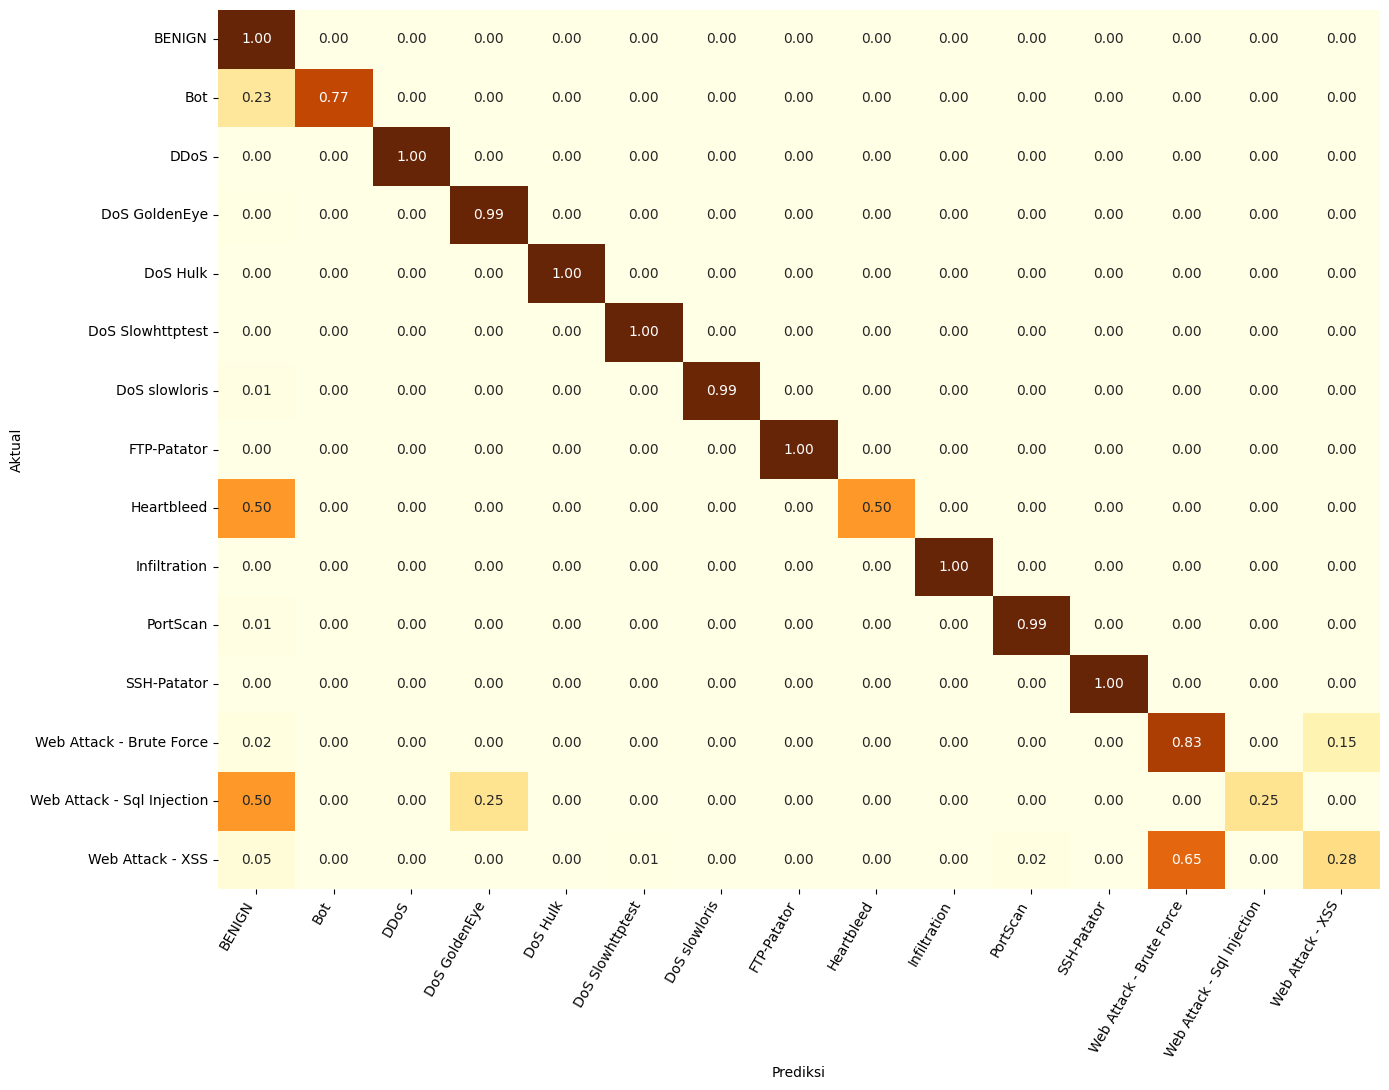

FP (normal dikira serangan): 299
FN (serangan lolos jadi normal): 417
PortScan -> diprediksi BENIGN: 197
BENIGN -> diprediksi PortScan: 196
DoS Hulk -> diprediksi BENIGN: 92
Bot -> diprediksi BENIGN: 88
Web Attack - XSS -> diprediksi Web Attack - Brute Force: 85
BENIGN -> diprediksi DoS Hulk: 52
Web Attack - Brute Force -> diprediksi Web Attack - XSS: 45
BENIGN -> diprediksi Bot: 35


In [8]:
cm = confusion_matrix(y_te, y_pred)

# confusion matrix dinormalisasi per kelas aktual
cmn = cm / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(14, 11))
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="YlOrBr", cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
plt.savefig(f"{ART}/confusion_matrix.png", dpi=200); plt.show()

# FP dan FN dari sudut pandang IDS (normal vs serangan)
b = list(le.classes_).index("BENIGN")
FP = int(((y_te == b) & (y_pred != b)).sum())
FN = int(((y_te != b) & (y_pred == b)).sum())
print("FP (normal dikira serangan):", FP)
print("FN (serangan lolos jadi normal):", FN)

# pasangan kelas yang paling sering tertukar
off = cm.copy(); np.fill_diagonal(off, 0)
for k in np.argsort(-off.ravel())[:8]:
    i, j = np.unravel_index(k, off.shape)
    print(f"{le.classes_[i]} -> diprediksi {le.classes_[j]}: {off[i, j]}")

### 7c. Simpan metrik (dipakai halaman Performa di web)

In [9]:
p, r, f1, s = precision_recall_fscore_support(
    y_te, y_pred, labels=range(len(le.classes_)), zero_division=0
)
imp = sorted(zip(feature_names, rf.feature_importances_.astype(float)), key=lambda t: -t[1])[:15]

metrics = {
    "accuracy": float(accuracy_score(y_te, y_pred)),
    "macro_f1": float(f1.mean()),
    "classes": list(le.classes_),
    "per_class": [{"label": c, "precision": float(p[i]), "recall": float(r[i]),
                   "f1": float(f1[i]), "support": int(s[i])} for i, c in enumerate(le.classes_)],
    "confusion_matrix": cm.tolist(),
    "false_positive": FP, "false_negative": FN,
    "feature_importance": [{"feature": k, "importance": v} for k, v in imp],
}
json.dump(metrics, open(f"{ART}/metrics.json", "w"), indent=2)
print("Akurasi:", round(metrics["accuracy"], 4), "| Macro F1:", round(metrics["macro_f1"], 4))

Akurasi: 0.9983 | Macro F1: 0.865


## 8. Grafik untuk laporan

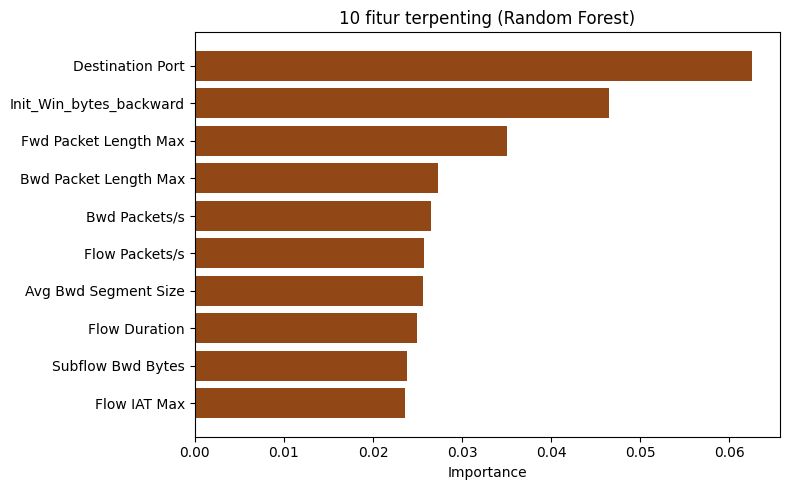

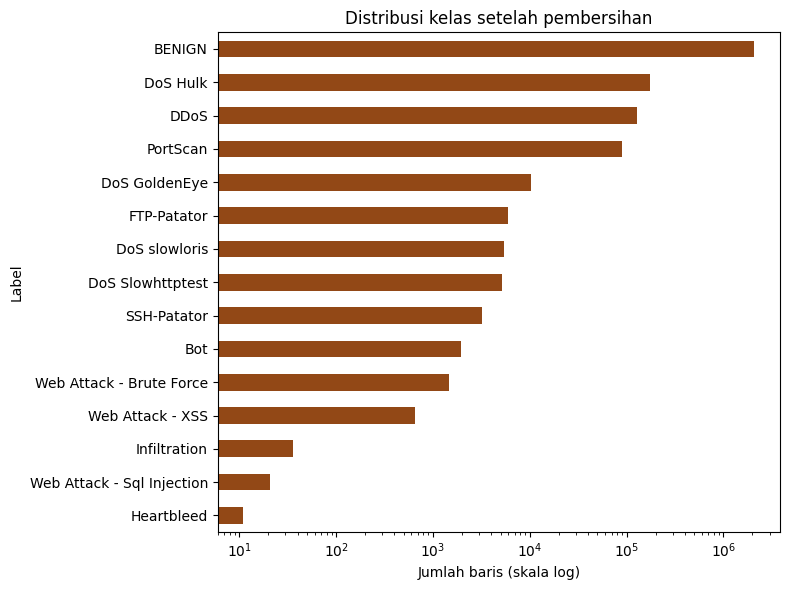

In [10]:
top = imp[:10][::-1]
plt.figure(figsize=(8, 5))
plt.barh([k for k, _ in top], [v for _, v in top], color="#924816")
plt.xlabel("Importance"); plt.title("10 fitur terpenting (Random Forest)")
plt.tight_layout(); plt.savefig(f"{ART}/feature_importance.png", dpi=200); plt.show()

df["Label"].value_counts().sort_values().plot(kind="barh", logx=True, color="#924816", figsize=(8, 6))
plt.xlabel("Jumlah baris (skala log)"); plt.title("Distribusi kelas setelah pembersihan")
plt.tight_layout(); plt.savefig(f"{ART}/distribusi_kelas.png", dpi=200); plt.show()

## 9. Analisis PortScan yang lolos (false negative)

In [11]:
ps = list(le.classes_).index("PortScan")
lolos = (y_te == ps) & (y_pred == b)
kena  = (y_te == ps) & (y_pred == ps)
cols = ["Destination Port", "Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Packets/s"]
print("PortScan lolos:", lolos.sum()); print(X_te[lolos][cols].describe().loc[["mean", "50%"]])
print("PortScan terdeteksi:", kena.sum()); print(X_te[kena][cols].describe().loc[["mean", "50%"]])

PortScan lolos: 197
      Destination Port  Flow Duration  Total Fwd Packets  \
mean       7597.304688   58139.148438           1.071066   
50%        3369.000000      49.000000           1.000000   

      Total Backward Packets  Flow Packets/s  
mean                1.050761    78451.835938  
50%                 1.000000    40816.328125  
PortScan terdeteksi: 17936
      Destination Port  Flow Duration  Total Fwd Packets  \
mean            8385.5  180235.546875           1.028211   
50%             3389.0      50.000000           1.000000   

      Total Backward Packets  Flow Packets/s  
mean                1.009255     72032.84375  
50%                 1.000000     40000.00000  


## 10. Ekspor artefak untuk Orang 2 dan 3

In [12]:
import sklearn
json.dump(feature_names, open(f"{ART}/feature_names.json", "w"))
json.dump(list(le.classes_), open(f"{ART}/classes.json", "w"))

te = X_te.copy()
te["Label"] = le.inverse_transform(y_te)
sample = pd.concat([g.sample(min(len(g), 8), random_state=RANDOM_STATE) for _, g in te.groupby("Label")])
sample.to_csv(f"{ART}/sample_flows.csv", index=False)

print("scikit-learn:", sklearn.__version__)
print("Ukuran model: %.0f MB" % (os.path.getsize(MODEL_PATH) / 1e6))
print("sample_flows.csv:", sample.shape)
print(sorted(os.listdir(ART)))

scikit-learn: 1.6.1
Ukuran model: 23 MB
sample_flows.csv: (109, 70)
['classes.json', 'confusion_matrix.png', 'distribusi_kelas.png', 'feature_importance.png', 'feature_names.json', 'metrics.json', 'model.joblib', 'sample_flows.csv']
